<a href="https://colab.research.google.com/github/msanders357517-lang/ALABAMA-INDEX-STUDY-MANAGER/blob/main/ALDOR_Manufactured_Trailers_Workflow.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ALDOR Manufactured Trailers Workflow

### How to run this notebook
1. Open this notebook in Google Colab.
2. Select **Runtime → Run all**.
3. Upload the ZIP containing your source tables, or select all CSV/XLSX tables together.
4. Review the charts and quality flags below. A ZIP downloads automatically with three Excel versions: the original formatted workbook (or parts), a records-only workbook, and a combined workbook with an interactive Pivot Analysis tab. Both combined workbooks use one tab whenever the data fits; if there are more than 1,048,575 data rows, it uses additional tabs to avoid losing records.

**No code changes are required.** Yellow length cells are estimates; yellow retail cells are MSRP substitutes. Positive original retail and recorded exact lengths are retained under the existing processing rules.

### Source tables
| Table | Required columns |
|---|---|
| configurations | configurationId, modelId, modelYear, sizeClassId |
| models | modelId, manufacturerId |
| manufacturers | manufacturerId, manufacturerName |
| sizeClasses | sizeClassId, subtypeId, sizeClassName, sizeClassMin, sizeClassMax, sizeClassUom |
| subTypes | subtypeId, subtypeName |
| values | configurationId, retail, msrp |
| specsTrailers | configurationId, specName, specValue |

Optional: Trailer Options (configurationId, specValue). The notebook recognizes tables by their headers.


## 1. Settings

> These settings control batch sizes, sheet limits and length estimation. Leave them unchanged for normal use.

In [3]:
# 1. Settings
# These settings control batch sizes, sheet limits and length estimation. Leave them unchanged for normal use.
# SETTINGS — no changes required. Do not edit code.
ROWS_PER_SHEET = 50_000
SHEETS_PER_WORKBOOK = 10
IMPORT_BATCH = 5_000
EXPORT_BATCH = 5_000
USE_TRAILER_OPTIONS_FALLBACK = True
USE_MSRP_FOR_LENGTH_ESTIMATING_WHEN_RETAIL_ZERO = True
ESTIMATE_ROUND_FT = 1.0  # Estimated feet rounded to nearest whole foot


## 2. Upload and check source tables

> Upload your files once. The notebook identifies the tables, checks required headers and converts them into a consistent format.

In [4]:
# 2. Upload and check source tables
# Upload your files once. The notebook identifies the tables, checks required headers and converts them into a consistent format.
# Upload inputs: ZIP(s), several CSVs, several XLSX files, or a mixture.
import os, pathlib, zipfile, shutil, csv, re, io, collections
from google.colab import files
source_dir=pathlib.Path('/content/trailer_tables')
source_dir.mkdir(exist_ok=True)
for old in source_dir.iterdir():
    if old.is_file(): old.unlink()

print('Upload a data ZIP or select your table CSV/XLSX files together.')
uploaded=files.upload()

candidates=[]
for filename in uploaded:
    pp=pathlib.Path(filename)
    if pp.suffix.lower()=='.zip':
        with zipfile.ZipFile(pp) as z:
            for item in z.infolist():
                if item.is_dir(): continue
                base=pathlib.PurePosixPath(item.filename.replace(chr(92),'/')).name
                if pathlib.Path(base).suffix.lower() not in ('.csv','.xlsx'): continue
                # Extract to unique temporary name, avoiding collisions from other ZIPs.
                dest=source_dir/('input_'+str(len(candidates)).zfill(3)+pathlib.Path(base).suffix.lower())
                with z.open(item) as src, open(dest,'wb') as dst:shutil.copyfileobj(src,dst)
                candidates.append((base,dest))
    elif pp.suffix.lower() in ('.csv','.xlsx'):
        dest=source_dir/('input_'+str(len(candidates)).zfill(3)+pp.suffix.lower())
        shutil.copyfile(pp,dest)
        candidates.append((pp.name,dest))
if not candidates: raise ValueError('Nothing uploaded. Select one ZIP or individual table CSV/XLSX files.')

# Header-based table identification, even when file names differ.
required_fields={
 'configurations':['configurationId','modelId','modelYear','sizeClassId'],
 'models':['modelId','manufacturerId'],
 'manufacturers':['manufacturerId','manufacturerName'],
 'sizeClasses':['sizeClassId','subtypeId','sizeClassName','sizeClassMin','sizeClassMax','sizeClassUom'],
 'subTypes':['subtypeId','subtypeName'],
 'values':['configurationId','retail','msrp'],
 'specsTrailers':['configurationId','specName','specValue'],
 'Trailer Options':['configurationId','specValue']
}

def get_headers(path):
    if path.suffix.lower()=='.csv':
        with open(path,encoding='utf-8-sig',errors='replace',newline='') as f:
            return [x.strip() for x in (next(csv.reader(f)) or [])]
    import openpyxl
    wb=openpyxl.load_workbook(path,read_only=True,data_only=True)
    try:return [str(x).strip() if x is not None else '' for x in next(wb.active.values)]
    finally:wb.close()

def count_rows(path):
    if path.suffix.lower()=='.csv':
        with open(path,'rb') as f:return max(0,sum(block.count(b'\n') for block in iter(lambda:f.read(1024*1024),b''))-1)
    import openpyxl
    wb=openpyxl.load_workbook(path,read_only=True,data_only=True)
    try:return max(0,wb.active.max_row-1)
    finally:wb.close()

matched={}
for given_name,path in candidates:
    try:hdr=set(get_headers(path))
    except Exception as exc:
        print('Skipping unreadable file:',given_name,str(exc));continue
    found=[name for name,fields in required_fields.items() if set(fields).issubset(hdr)]
    # The largest set of required columns determines the matching table; never confuse opts with specsTrailers.
    if not found:
        print('Unrecognized headers, ignored:',given_name);continue
    found.sort(key=lambda n:len(required_fields[n]),reverse=True)
    name=found[0]
    # Prefer matching filename to distinguish ambiguous but compatible exports.
    name_hint=re.sub(r'[^a-z]','',given_name.lower())
    if 'traileroptions' in name_hint and 'Trailer Options' in found:name='Trailer Options'
    if name=='Trailer Options' and 'specsTrailers' in found:name='specsTrailers'
    rows=count_rows(path)
    prior=matched.get(name)
    if prior is None or rows>prior[2]:matched[name]=(given_name,path,rows)

required=[name for name in required_fields if name!='Trailer Options']
missing=[name for name in required if name not in matched]
if missing:
    raise ValueError('Missing tables: '+', '.join(missing)+'; expected column headers are listed in the first notebook cell.')

# Normalize selected source to canonical CSV names so the analysis code works unchanged.
# Reads XLSX as a stream to avoid loading big spreadsheets entirely into RAM.
def canonicalize(path,target):
    if path.suffix.lower()=='.csv':
        shutil.copyfile(path,target);return
    import openpyxl
    book=openpyxl.load_workbook(path,read_only=True,data_only=True)
    try:
        with open(target,'w',newline='',encoding='utf-8') as f:
            writer=csv.writer(f)
            for row in book.active.values:writer.writerow(['' if v is None else v for v in row])
    finally:book.close()
for name,(original,source,rows) in matched.items():
    canonicalize(source,source_dir/(name+'.csv'))
    print(f'{name}: {rows:,} rows, from {original}')
print('Input table validation complete. Optional Trailer Options:', 'yes' if 'Trailer Options' in matched else 'no')

Upload a data ZIP or select your table CSV/XLSX files together.


Saving ALDOR_Manufactured_Trailers_Source_Tables.zip to ALDOR_Manufactured_Trailers_Source_Tables.zip
configurations: 466,673 rows, from configurations.csv
models: 3,224 rows, from models.csv
manufacturers: 163 rows, from manufacturers.csv
sizeClasses: 44 rows, from sizeClasses.csv
subTypes: 17 rows, from subTypes.csv
values: 466,673 rows, from values.csv
specsTrailers: 1,048,575 rows, from specsTrailers.csv
Trailer Options: 10,669 rows, from Trailer Options.csv
Input table validation complete. Optional Trailer Options: yes


## 3. Combine records and calculate lengths

> Join source tables by their IDs. Preserve existing pricing and measurement rules, repair date-like ranges, and estimate missing lengths using comparable prices where possible.

In [5]:
# 3. Combine records and calculate lengths
# Join source tables by their IDs. Preserve existing pricing and measurement rules, repair date-like ranges, and estimate missing lengths using comparable prices where possible.
import csv, sqlite3, math, re, time, os
from tqdm.auto import tqdm
DB='/content/trailer_master_work.sqlite'
if os.path.exists(DB):os.remove(DB)
con=sqlite3.connect(DB)
con.execute('PRAGMA journal_mode=OFF')
con.execute('PRAGMA synchronous=OFF')
con.execute('PRAGMA temp_store=MEMORY')
con.execute('PRAGMA cache_size=-64000')

# Protect length ranges that an earlier Excel export converted to month/date labels.
# The original numeric lower/upper bounds are authoritative for these rows.
MONTH_RANGE = re.compile(r"^(?:\d{1,2}[- /](?:Jan|Feb|Mar|Apr|May|Jun|Jul|Aug|Sep|Oct|Nov|Dec)|(?:Jan|Feb|Mar|Apr|May|Jun|Jul|Aug|Sep|Oct|Nov|Dec)[- /]\d{1,2})$", re.I)
fixed_range_labels = []
def restore_range_label(d):
    label = str(d.get('sizeClassName') or '').strip()
    low = str(d.get('sizeClassMin') or '').strip()
    high = str(d.get('sizeClassMax') or '').strip()
    if MONTH_RANGE.fullmatch(label) and re.fullmatch(r"\d+(?:\.\d+)?",low) and re.fullmatch(r"\d+(?:\.\d+)?",high):
        if 0 < float(low) <= float(high):
            clean = low+'-'+high
            fixed_range_labels.append((label,clean))
            d['sizeClassName'] = clean
    return d

def load_csv(name,table,fields):
    con.execute(f'CREATE TABLE "{table}" ('+', '.join(f'"{x}" TEXT' for x in fields)+')')
    sql=f'INSERT INTO "{table}" VALUES ('+','.join('?' for x in fields)+')'
    count=0; buf=[]
    with open(source_dir/name,newline='',encoding='utf-8-sig',errors='replace') as file:
        reader=csv.DictReader(file)
        missing=set(fields)-set(reader.fieldnames or [])
        if missing:raise ValueError(f'{name} missing fields: {missing}')
        for d in reader:
            if table == 'sc':
                d = restore_range_label(d)
            buf.append([d.get(f,'') for f in fields])
            if len(buf)>=IMPORT_BATCH:
                con.executemany(sql,buf);count+=len(buf);buf=[]
        if buf:con.executemany(sql,buf);count+=len(buf)
    con.commit();print(f'Loaded {name}: {count:,} rows',flush=True)

load_csv('configurations.csv','cfg',['configurationId','modelId','modelYear','sizeClassId'])
load_csv('models.csv','mod',['modelId','manufacturerId'])
load_csv('manufacturers.csv','mfr',['manufacturerId','manufacturerName'])
load_csv('sizeClasses.csv','sc',['sizeClassId','subtypeId','sizeClassName','sizeClassMin','sizeClassMax','sizeClassUom'])
print('Restored date-looking size-class labels:', fixed_range_labels if fixed_range_labels else 'none', flush=True)
load_csv('subTypes.csv','st',['subtypeId','subtypeName'])
load_csv('values.csv','vals',['configurationId','retail','msrp'])
load_csv('specsTrailers.csv','spec',['configurationId','specName','specValue'])
if USE_TRAILER_OPTIONS_FALLBACK and (source_dir/'Trailer Options.csv').is_file():
    load_csv('Trailer Options.csv','opts',['configurationId','specValue'])
else:con.execute('CREATE TABLE opts(configurationId TEXT,specValue TEXT)')
for tab,col in [('cfg','configurationId'),('mod','modelId'),('mfr','manufacturerId'),('sc','sizeClassId'),('st','subtypeId'),('vals','configurationId'),('spec','configurationId'),('opts','configurationId')]:
    con.execute(f'CREATE INDEX i_{tab} ON "{tab}"("{col}")')
con.commit()

# Prefer actual recorded length, then Trailer Options, then size-class range.
# Accept only plainly feet-formatted exact lengths, not arbitrary specifications.
def parse_measure(s):
    if s is None:return ('',None,None)
    s=str(s).strip().lower().replace('feet','ft').replace('foot','ft')
    if not s:return ('',None,None)
    m=re.fullmatch(r'(\d+(?:\.\d+)?)\s*(?:ft|\')?\s*[-–]\s*(\d+(?:\.\d+)?)\s*(?:ft|\')?',s)
    if m:
        lo,hi=map(float,m.groups())
        return ('range',lo,hi) if 0<lo<=hi else ('',None,None)
    m=re.fullmatch(r'(\d+(?:\.\d+)?)\s*\'\s*(\d+(?:\.\d+)?)\s*(?:"|in)?',s)
    if m:
        f,inch=map(float,m.groups())
        return ('exact',f+inch/12,f+inch/12) if inch<12 else ('',None,None)
    m=re.fullmatch(r'(\d+(?:\.\d+)?)\s*(?:ft)?',s)
    if m:
        f=float(m.group(1))
        return ('exact',f,f) if f>0 else ('',None,None)
    return ('',None,None)
con.create_function('meas_kind',1,lambda x:parse_measure(x)[0])
con.create_function('meas_low',1,lambda x:parse_measure(x)[1])
con.create_function('meas_high',1,lambda x:parse_measure(x)[2])
print('Aggregating available specifications and prices...',flush=True)
con.execute('''CREATE TABLE measured AS SELECT configurationId,MAX(NULLIF(TRIM(specValue),'')) AS length
 FROM spec WHERE LOWER(TRIM(specName))='length' GROUP BY configurationId''')
con.execute('CREATE UNIQUE INDEX i_measured ON measured(configurationId)')
con.execute('''CREATE TABLE option_length AS SELECT configurationId,MAX(NULLIF(TRIM(specValue),'')) AS length
 FROM opts GROUP BY configurationId''')
con.execute('CREATE UNIQUE INDEX i_option_length ON option_length(configurationId)')
con.execute('''CREATE TABLE prices AS SELECT configurationId,
 MAX(CAST(NULLIF(TRIM(retail),'') AS REAL)) AS retail,
 MAX(CAST(NULLIF(TRIM(msrp),'') AS REAL)) AS msrp
 FROM vals GROUP BY configurationId''')
con.execute('CREATE UNIQUE INDEX i_prices ON prices(configurationId)')
con.commit()
print('Joining configurations...',flush=True)
con.execute('''CREATE TABLE joined AS SELECT c.configurationId,c.modelYear,m.manufacturerName,t.subtypeName,
 c.sizeClassId,s.sizeClassName,s.sizeClassMin,s.sizeClassMax,s.sizeClassUom,
 a.length AS actualLength,o.length AS optionLength,p.retail,p.msrp
 FROM cfg c JOIN mod mo ON c.modelId=mo.modelId
 JOIN mfr m ON mo.manufacturerId=m.manufacturerId
 JOIN sc s ON c.sizeClassId=s.sizeClassId
 JOIN st t ON s.subtypeId=t.subtypeId
 LEFT JOIN measured a ON c.configurationId=a.configurationId
 LEFT JOIN option_length o ON c.configurationId=o.configurationId
 LEFT JOIN prices p ON c.configurationId=p.configurationId''')
con.commit()

# Grouping includes model year, manufacturer, subtype and identical sizeClassId.
# Keep one row per configuration. Exact measurements are NEVER estimated.
con.execute('''CREATE TABLE base AS SELECT configurationId,modelYear,manufacturerName,subtypeName,sizeClassId,
 COALESCE(sizeClassName,'') AS sizeClassName,retail,msrp,
 CASE WHEN meas_kind(actualLength) IN ('exact','range') THEN TRIM(actualLength)
      WHEN meas_kind(optionLength) IN ('exact','range') THEN TRIM(optionLength)
      WHEN LOWER(TRIM(sizeClassUom))='ft' AND CAST(sizeClassMin AS REAL)>0
       AND CAST(sizeClassMax AS REAL)>=CAST(sizeClassMin AS REAL)
      THEN TRIM(sizeClassMin)||'-'||TRIM(sizeClassMax)||' ft' ELSE '' END AS specValue,
 CASE WHEN meas_kind(actualLength)='exact' THEN 'specsTrailers (exact)'
      WHEN meas_kind(actualLength)='range' THEN 'specsTrailers (recorded range)'
      WHEN meas_kind(optionLength)='exact' THEN 'Trailer Options (exact)'
      WHEN meas_kind(optionLength)='range' THEN 'Trailer Options (recorded range)'
      WHEN LOWER(TRIM(sizeClassUom))='ft' AND CAST(sizeClassMin AS REAL)>0
       AND CAST(sizeClassMax AS REAL)>=CAST(sizeClassMin AS REAL)
      THEN 'sizeClasses (range)' ELSE 'Missing' END AS lengthSource
 FROM joined''')
con.execute('CREATE INDEX i_base_groups ON base(modelYear,manufacturerName,subtypeName,sizeClassId)')
con.execute('''CREATE TABLE estimate_input AS SELECT b.*,
 CASE WHEN retail>0 THEN retail WHEN ? AND msrp>0 THEN msrp ELSE NULL END AS rankPrice,
 CASE WHEN retail>0 THEN 'Original retail' WHEN ? AND msrp>0 THEN 'MSRP proxy' ELSE 'No usable price' END AS estimatePriceSource,
 CASE WHEN lengthSource LIKE '%(exact)' THEN NULL ELSE meas_low(specValue) END AS lowerFt,
 CASE WHEN lengthSource LIKE '%(exact)' THEN NULL ELSE meas_high(specValue) END AS upperFt
 FROM base b''',(int(USE_MSRP_FOR_LENGTH_ESTIMATING_WHEN_RETAIL_ZERO),)*2)
con.execute('''CREATE TABLE ranking AS SELECT modelYear,manufacturerName,subtypeName,sizeClassId,estimatePriceSource,
 MIN(rankPrice) minPrice,MAX(rankPrice) maxPrice
 FROM estimate_input WHERE rankPrice>0 AND lowerFt IS NOT NULL AND upperFt IS NOT NULL
 GROUP BY modelYear,manufacturerName,subtypeName,sizeClassId,estimatePriceSource''')
con.execute('CREATE INDEX i_ranking ON ranking(modelYear,manufacturerName,subtypeName,sizeClassId,estimatePriceSource)')
con.commit()
def estimate(source,lo,hi,p,pmin,pmax):
    if source and source.endswith('(exact)'):return None
    if any(v is None for v in (lo,hi,p,pmin,pmax)) or lo<=0 or hi<lo or p<=0:return None
    raw=(lo+hi)/2 if pmax==pmin else lo+(hi-lo)*max(0,min(1,(p-pmin)/(pmax-pmin)))
    est=math.floor(raw/ESTIMATE_ROUND_FT + 0.5)*ESTIMATE_ROUND_FT
    return max(lo,min(hi,est))
con.create_function('estimated_length',6,estimate)
con.execute('''CREATE TABLE final_data AS
 SELECT b.modelYear,b.manufacturerName,b.subtypeName,b.sizeClassId,b.specValue,b.sizeClassName,b.retail,b.msrp,b.lengthSource,
 estimated_length(b.lengthSource,b.lowerFt,b.upperFt,b.rankPrice,r.minPrice,r.maxPrice) estimatedExactLength,
 b.estimatePriceSource,
 CASE WHEN b.lengthSource LIKE '%(exact)' THEN 'Not needed (exact length recorded)'
 WHEN b.lowerFt IS NULL OR b.upperFt IS NULL THEN 'Unavailable: no usable range'
 WHEN b.rankPrice IS NULL OR b.rankPrice<=0 THEN 'Unavailable: no positive price'
 WHEN r.minPrice=r.maxPrice THEN 'Midpoint: no price variation'
 ELSE 'Linear price-ranking heuristic within group' END estimateMethod
 FROM estimate_input b LEFT JOIN ranking r ON b.modelYear=r.modelYear
 AND b.manufacturerName=r.manufacturerName AND b.subtypeName=r.subtypeName
 AND b.sizeClassId=r.sizeClassId AND b.estimatePriceSource=r.estimatePriceSource''')
con.commit()

# Each missing-length configuration receives its OWN price-ranked length estimate.
# Do NOT average lengths across different prices: that would erase the price signal.
# A recorded exact length always takes precedence over any estimate.
# Original retail is preserved; MSRP is substituted only where retail is zero/missing.
con.execute('''CREATE TABLE export_review AS
 SELECT f.*, f.estimatedExactLength AS reviewedEstimateFt,
        0 AS averagedComparableCount
 FROM final_data f''')
con.commit()
print('Length-estimation rule: individual price-ranked estimates; no group-length averaging.')
print('Retail-priority rule: positive original retail is never averaged or highlighted.')

num_rows=con.execute('SELECT COUNT(*) FROM export_review').fetchone()[0]
print('Total configurations for export:',f'{num_rows:,}')
print('2026 (rows, zero retail, positive MSRP):',con.execute("SELECT COUNT(*), SUM(CASE WHEN retail=0 THEN 1 ELSE 0 END),SUM(CASE WHEN msrp>0 THEN 1 ELSE 0 END) FROM export_review WHERE modelYear='2026'").fetchone())

coverage=list(con.execute("""SELECT modelYear, COUNT(*),
 SUM(CASE WHEN lengthSource LIKE '%(exact)' THEN 1 ELSE 0 END),
 SUM(CASE WHEN reviewedEstimateFt IS NOT NULL THEN 1 ELSE 0 END),
 SUM(CASE WHEN retail=0 AND msrp>0 THEN 1 ELSE 0 END),
 SUM(CASE WHEN lengthSource LIKE '%(range)' THEN 1 ELSE 0 END)
 FROM export_review GROUP BY modelYear ORDER BY modelYear"""))


Loaded configurations.csv: 466,673 rows
Loaded models.csv: 3,224 rows
Loaded manufacturers.csv: 163 rows
Loaded sizeClasses.csv: 44 rows
Restored date-looking size-class labels: none
Loaded subTypes.csv: 17 rows
Loaded values.csv: 466,673 rows
Loaded specsTrailers.csv: 1,048,575 rows
Loaded Trailer Options.csv: 10,669 rows
Aggregating available specifications and prices...
Joining configurations...
Length-estimation rule: individual price-ranked estimates; no group-length averaging.
Retail-priority rule: positive original retail is never averaged or highlighted.
Total configurations for export: 466,673
2026 (rows, zero retail, positive MSRP): (19098, 19098, 19098)


## 4. Interactive pivot-style dashboard

> Select a manufacturer, subtype and displayed trailer length (or All). Switch between average retail, sum of retail and record counts. Compare the selected records with the overall market and the same subtype/length across brands. Review pricing and length coverage by year. Original retail takes priority; MSRP fills missing or nonpositive retail.


YEAR COVERAGE — counts by model year


,Year,Records,Recorded,Estimated,Missing_length,Original_retail,MSRP_proxy,Missing_price
0,1990,4226,483,3743,0,4226,0,0
1,1991,4226,489,3737,0,4226,0,0
2,1992,4386,474,3912,0,4386,0,0
3,1993,4623,478,4145,0,4623,0,0
4,1994,5384,897,4487,0,5384,0,0
5,1995,5645,984,4661,0,5645,0,0
6,1996,5755,987,4768,0,5755,0,0
7,1997,6375,562,5813,0,6375,0,0
8,1998,6409,476,5933,0,6409,0,0
9,1999,7018,475,6543,0,7018,0,0


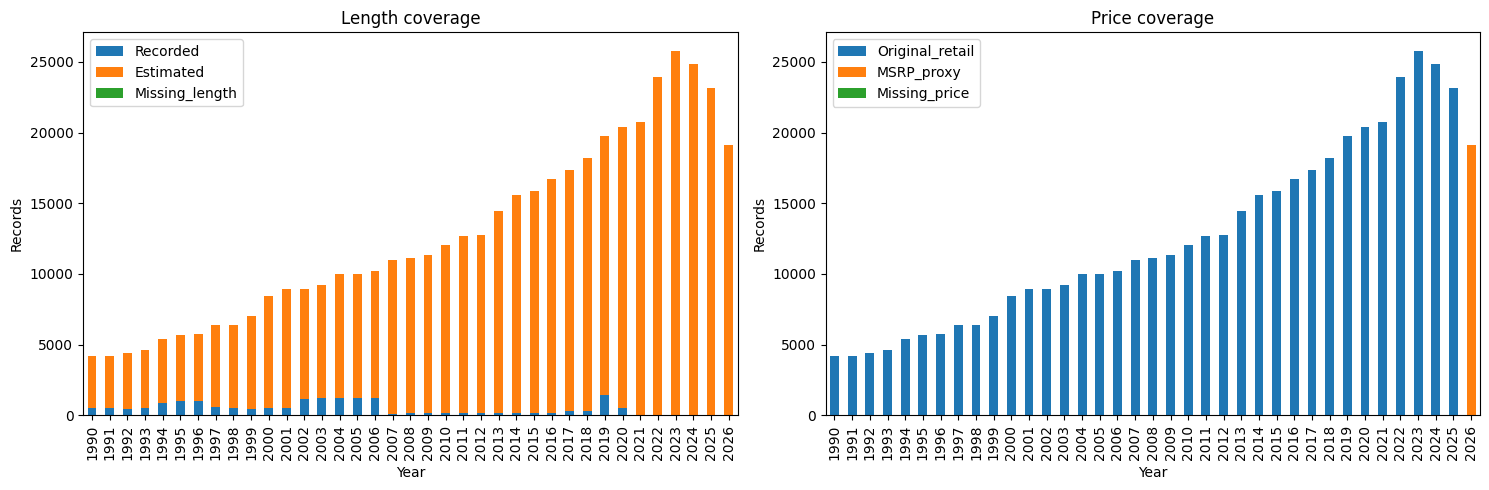

ALL MANUFACTURERS — annual effective retail (retail first, MSRP fallback)


,Year,Records,Priced,MSRP_count,Mean_price,MSRP_pct
0,1990,4226,4226,0,4216.35,0.0
1,1991,4226,4226,0,4359.33,0.0
2,1992,4386,4386,0,4400.80,0.0
3,1993,4623,4623,0,4418.11,0.0
4,1994,5384,5384,0,4354.90,0.0
5,1995,5645,5645,0,4712.56,0.0
6,1996,5755,5755,0,4800.24,0.0
7,1997,6375,6375,0,4827.75,0.0
8,1998,6409,6409,0,5851.99,0.0
9,1999,7018,7018,0,6047.35,0.0


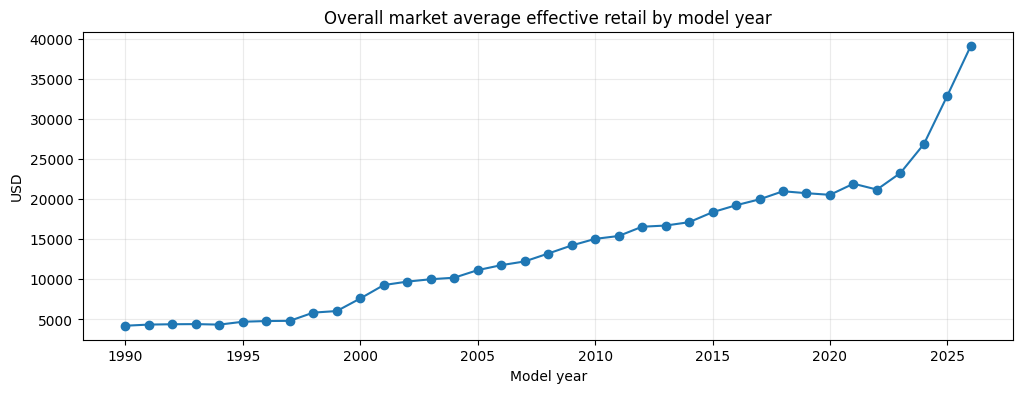

Use average retail for valuation comparisons. Sum of retail is sensitive to record counts. MSRP is a proxy; estimated lengths are not independent validation.


In [6]:
# 4. Review coverage and data quality
# Review year-by-year completeness, then choose a manufacturer and subtype to see annual price and length trends. Correlation uses paired individual observations within each group; estimated lengths are not independent evidence of quality.
# Calculate coverage and quality summaries from the exact same rows used for export.
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
import ipywidgets as widgets

# Separate actual prices from MSRP proxies and recorded lengths from estimates.
# Use the exported whole-foot estimate so charts match the final spreadsheet.
con.execute("DROP VIEW IF EXISTS quality_rows")
con.execute("""CREATE TEMP VIEW quality_rows AS SELECT modelYear, manufacturerName, subtypeName,
 CASE WHEN lengthSource LIKE '%(exact)' THEN 'Recorded' WHEN reviewedEstimateFt IS NOT NULL THEN 'Estimated' ELSE 'Missing' END AS length_basis,
 CASE WHEN retail>0 THEN 'Original retail' WHEN msrp>0 THEN 'MSRP proxy' ELSE 'Missing' END AS price_basis,
 CASE WHEN lengthSource LIKE '%(exact)' THEN meas_low(specValue) WHEN reviewedEstimateFt IS NOT NULL THEN CAST(reviewedEstimateFt+0.5 AS INTEGER) END AS feet,
 CASE WHEN retail>0 THEN retail WHEN msrp>0 THEN msrp END AS price
 FROM export_review""")
coverage_df=pd.read_sql_query("""SELECT modelYear AS Year, COUNT(*) AS Records,
 SUM(length_basis='Recorded') AS Recorded, SUM(length_basis='Estimated') AS Estimated,
 SUM(length_basis='Missing') AS Missing_length, SUM(price_basis='Original retail') AS Original_retail,
 SUM(price_basis='MSRP proxy') AS MSRP_proxy, SUM(price_basis='Missing') AS Missing_price
 FROM quality_rows GROUP BY modelYear ORDER BY CAST(modelYear AS INTEGER)""",con)
# Aggregate only valid paired observations. These sufficient statistics avoid loading all raw records into memory.
stats=pd.read_sql_query("""SELECT modelYear AS Year, manufacturerName AS Manufacturer, subtypeName AS Subtype,
 length_basis AS Length_basis, price_basis AS Price_basis, COUNT(*) AS N,
 SUM(feet) AS sx, SUM(price) AS sy, SUM(feet*feet) AS sxx, SUM(price*price) AS syy, SUM(feet*price) AS sxy
 FROM quality_rows WHERE feet>0 AND price>0 GROUP BY 1,2,3,4,5""",con)

def summarize(frame, keys):
    # Pearson r measures linear association, not causation. Require at least 5 pairs and variation in both variables.
    g=frame.groupby(keys,dropna=False)[['N','sx','sy','sxx','syy','sxy']].sum().reset_index()
    g['Mean_feet']=g.sx/g.N; g['Mean_price']=g.sy/g.N
    vx=(g.N*g.sxx-g.sx**2).clip(lower=0); vy=(g.N*g.syy-g.sy**2).clip(lower=0)
    den=np.sqrt(vx*vy)
    g['Pearson_r']=((g.N*g.sxy-g.sx*g.sy)/den.where(den>0)).clip(-1,1).where(g.N>=5)
    g['Review']=np.select([g.Length_basis.eq('Estimated'),g.Pearson_r.isna(),g.Pearson_r<0.3,g.Pearson_r<0.7],['Price-derived; not independent validation','Insufficient pairs or variation','Review weak/negative association','Moderate positive association'],default='Strong positive association')
    return g.drop(columns=['sx','sy','sxx','syy','sxy'])
annual=summarize(stats,['Year','Manufacturer','Subtype','Length_basis','Price_basis'])
quality_summary=summarize(stats,['Manufacturer','Subtype','Length_basis','Price_basis'])
print('YEAR COVERAGE — counts by model year')
display(coverage_df)
if not coverage_df.empty:
    fig,ax=plt.subplots(1,2,figsize=(15,5))
    coverage_df.set_index('Year')[['Recorded','Estimated','Missing_length']].plot.bar(stacked=True,ax=ax[0],title='Length coverage')
    coverage_df.set_index('Year')[['Original_retail','MSRP_proxy','Missing_price']].plot.bar(stacked=True,ax=ax[1],title='Price coverage')
    for a in ax: a.set_ylabel('Records'); a.tick_params(axis='x',labelrotation=90)
    plt.tight_layout(); plt.show(); plt.close(fig)

# Price averages use ALL positively priced records, even if length is missing.
# Combine original retail and fallback MSRP into one effective price series.
price_totals=pd.read_sql_query("""SELECT modelYear AS Year, manufacturerName AS Manufacturer,
 subtypeName AS Subtype, COUNT(*) AS Records, COUNT(price) AS Priced,
 SUM(CASE WHEN price_basis='MSRP proxy' THEN 1 ELSE 0 END) AS MSRP_count,
 SUM(price) AS Price_sum FROM quality_rows GROUP BY 1,2,3""",con)
def price_summary(keys):
    g=price_totals.groupby(keys,dropna=False)[['Records','Priced','MSRP_count','Price_sum']].sum().reset_index()
    g['Mean_price']=g.Price_sum/g.Priced.replace(0,np.nan)
    g['MSRP_pct']=100*g.MSRP_count/g.Priced.replace(0,np.nan)
    return g.drop(columns='Price_sum').sort_values('Year')
market_prices=price_summary(['Year'])
brand_prices=price_summary(['Year','Manufacturer'])
subtype_prices=price_summary(['Year','Subtype'])
brand_subtype_prices=price_summary(['Year','Manufacturer','Subtype'])
# Annual averages are weighted by the number of valid prices, not the number of brands.
print('ALL MANUFACTURERS — annual effective retail (retail first, MSRP fallback)')
display(market_prices.round(2))
if not market_prices.empty:
    fig,ax=plt.subplots(figsize=(12,4))
    ax.plot(pd.to_numeric(market_prices.Year),market_prices.Mean_price,marker='o')
    ax.set(title='Overall market average effective retail by model year',xlabel='Model year',ylabel='USD'); ax.grid(alpha=.25)
    plt.show(); plt.close(fig)
# Combine pricing sources for primary length/price analysis, retaining length provenance.
combined=stats.copy(); combined['Price_basis']='Retail first / MSRP fallback'
annual_combined=summarize(combined,['Year','Manufacturer','Subtype','Length_basis','Price_basis'])
quality_combined=summarize(combined,['Manufacturer','Subtype','Length_basis','Price_basis'])
# Precompute the grouped curve data so the controls still work after Excel export closes SQLite.
length_price=pd.read_sql_query("""SELECT manufacturerName AS Manufacturer,subtypeName AS Subtype, modelYear AS Year,
 length_basis AS Length_basis, feet AS Feet, AVG(price) AS Mean_price, COUNT(*) AS N
 FROM quality_rows WHERE feet>0 AND price>0 GROUP BY 1,2,3,4,5 ORDER BY 3,5""",con)
# Build a compact pivot-style data cube using the SAME displayed length and effective retail as Excel.
# Keep counts and sums, so averages remain weighted correctly even when filters are changed.
pivot_data=pd.read_sql_query('''SELECT modelYear AS Year, manufacturerName AS Manufacturer,
 subtypeName AS Subtype,
 CASE WHEN lengthSource LIKE '%(exact)' THEN COALESCE(specValue,'')
 WHEN reviewedEstimateFt IS NOT NULL THEN printf('%d''0"',CAST(reviewedEstimateFt+0.5 AS INTEGER)) ELSE '' END AS Length,
 COUNT(*) AS Records,
 SUM(CASE WHEN retail>0 THEN 1 ELSE 0 END) AS Original_retail,
 SUM(CASE WHEN (retail IS NULL OR retail<=0) AND msrp>0 THEN 1 ELSE 0 END) AS MSRP_proxy,
 SUM(CASE WHEN retail>0 THEN retail WHEN msrp>0 THEN msrp ELSE 0 END) AS Price_sum,
 SUM(CASE WHEN lengthSource LIKE '%(exact)' THEN 1 ELSE 0 END) AS Recorded,
 SUM(CASE WHEN COALESCE(lengthSource,'') NOT LIKE '%(exact)' AND reviewedEstimateFt IS NOT NULL THEN 1 ELSE 0 END) AS Estimated
 FROM export_review GROUP BY 1,2,3,4''',con)
pivot_data['Year']=pd.to_numeric(pivot_data.Year,errors='coerce')
pivot_data=pivot_data.dropna(subset=['Year']).copy()
pivot_data['Year']=pivot_data.Year.astype(int)
for c in ['Manufacturer','Subtype','Length']: pivot_data[c]=pivot_data[c].fillna('')
pivot_data['Priced']=pivot_data.Original_retail+pivot_data.MSRP_proxy
pivot_data['Missing_price']=pivot_data.Records-pivot_data.Priced
pivot_data['Missing_length']=pivot_data.Records-pivot_data.Recorded-pivot_data.Estimated
# All years in the observed dataset, including internal gaps; missing years are not zero-dollar prices.
if not pivot_data.empty:
    years=pd.Index(range(pivot_data.Year.min(),pivot_data.Year.max()+1),name='Year')
    fields=['Records','Priced','Original_retail','MSRP_proxy','Missing_price','Recorded','Estimated','Missing_length','Price_sum']
    def by_year(frame):
        g=frame.groupby('Year')[fields].sum().reindex(years,fill_value=0)
        g['Average_retail']=g.Price_sum/g.Priced.replace(0,np.nan)
        g['Sum_retail']=g.Price_sum.where(g.Priced>0)
        g['MSRP_pct']=100*g.MSRP_proxy/g.Priced.replace(0,np.nan)
        return g
    style={'description_width':'initial'}
    m=widgets.Dropdown(description='Manufacturer:',style=style,layout=widgets.Layout(width='95%'))
    t=widgets.Dropdown(description='Subtype:',style=style,layout=widgets.Layout(width='95%'))
    l=widgets.Dropdown(description='Trailer length:',style=style,layout=widgets.Layout(width='95%'))
    metric=widgets.ToggleButtons(options=[('Average retail','Average_retail'),('Sum of retail','Sum_retail'),('Record count','Records')],description='Display:',style=style)
    output=widgets.Output()
    def options(series,missing):
        return [('All',None)]+[(v or missing,v) for v in sorted(series.unique())]
    def subset(frame,col,value):
        return frame if value is None else frame[frame[col]==value]
    def sync_filters(*args):
        b=subset(pivot_data,'Manufacturer',m.value)
        old=t.value; t.options=options(b.Subtype,'Missing subtype'); t.value=old if old in [v for _,v in t.options] else None
        sync_lengths()
    def sync_lengths(*args):
        b=subset(subset(pivot_data,'Manufacturer',m.value),'Subtype',t.value)
        old=l.value; l.options=options(b.Length,'Missing length'); l.value=old if old in [v for _,v in l.options] else None
        render()
    def render(*args):
        with output:
            output.clear_output(wait=True)
            brand=subset(pivot_data,'Manufacturer',m.value)
            comparable=subset(subset(pivot_data,'Subtype',t.value),'Length',l.value)
            chosen=subset(comparable,'Manufacturer',m.value)
            g=by_year(chosen); comp=by_year(comparable); market=by_year(pivot_data); bg=by_year(brand)
            label=' / '.join(str(v) if v else 'All or missing' for v in (m.value,t.value,l.value))
            print('SELECTED RECORDS:',label)
            # Pivot table: same filter fields as Excel, with both sum and weighted average for interpretation.
            display(g[['Records','Priced','Original_retail','MSRP_proxy','Average_retail','Sum_retail','MSRP_pct']].round(2))
            print(f"Grand total: {int(g.Records.sum()):,} records; {int(g.Priced.sum()):,} priced; sum ${g.Price_sum.sum():,.2f}; weighted average ${g.Price_sum.sum()/g.Priced.sum():,.2f}" if g.Priced.sum() else 'No usable prices for this selection.')
            fig,axes=plt.subplots(3,2,figsize=(16,13)); ax=axes.flat
            col=metric.value; unit='Records' if col=='Records' else 'USD'
            ax[0].plot(years,g[col],marker='o'); ax[0].set(title='Selected records — annual trend',ylabel=unit)
            ax[1].bar(years,g[col]); ax[1].set(title='Selected records — annual bars',ylabel=unit)
            ax[2].plot(years,bg.Average_retail,label=m.value or 'All manufacturers',marker='o'); ax[2].plot(years,market.Average_retail,label='Overall market',linestyle='--'); ax[2].set(title='Brand vs. overall market — average retail',ylabel='USD'); ax[2].legend()
            ax[3].plot(years,g.Average_retail,label='Selected manufacturer',marker='o'); ax[3].plot(years,comp.Average_retail,label='All manufacturers, same subtype and length filters',linestyle='--'); ax[3].set(title='Like-for-like market — average retail',ylabel='USD'); ax[3].legend(fontsize=8)
            for a,frame,title in [(ax[4],market,'Overall year coverage — pricing'),(ax[5],g,'Selected year coverage — pricing')]:
                bottom=np.zeros(len(years))
                for c in ['Original_retail','MSRP_proxy','Missing_price']:
                    a.bar(years,frame[c],bottom=bottom,label=c); bottom+=frame[c].to_numpy()
                a.set(title=title,ylabel='Records'); a.legend(fontsize=8)
            for a in ax: a.set_xlabel('Model year'); a.grid(axis='y',alpha=.2)
            plt.tight_layout(); plt.show(); plt.close(fig)
            fig,ax2=plt.subplots(figsize=(13,4)); bottom=np.zeros(len(years))
            for c in ['Recorded','Estimated','Missing_length']:
                ax2.bar(years,g[c],bottom=bottom,label=c); bottom+=g[c].to_numpy()
            ax2.set(title='Selected year coverage — recorded vs estimated lengths',xlabel='Model year',ylabel='Records'); ax2.legend(); plt.tight_layout(); plt.show(); plt.close(fig)
            # Correlation is evaluated across lengths within each year, not within a fixed-length selection.
            a=subset(subset(annual_combined,'Manufacturer',m.value),'Subtype',t.value)
            if l.value is not None: print('Correlation review below uses all lengths for the selected brand/subtype; a single fixed length cannot establish length–price correlation.')
            display(a[['Year','Manufacturer','Subtype','Length_basis','N','Mean_feet','Mean_price','Pearson_r','Review']].round(2))
    m.options=options(pivot_data.Manufacturer,'Missing manufacturer'); m.value=None
    sync_filters()
    m.observe(sync_filters,names='value'); t.observe(sync_lengths,names='value'); l.observe(render,names='value'); metric.observe(render,names='value')
    display(widgets.VBox([m,t,l,metric,output]))
else:
    print('No valid model years available for dashboard.')
print('Use average retail for valuation comparisons. Sum of retail is sensitive to record counts. MSRP is a proxy; estimated lengths are not independent validation.')


## 5. Export three Excel versions

> The ZIP includes the original full workbook, a combined records-only workbook, and a combined workbook with a second tab for interactive pivot-style price analysis. Select manufacturer, subtype and length in the yellow dropdown cells. The analysis uses the same grouped records as Step 4, with annual averages, totals, counts, brand and market comparisons, and coverage charts. The analysis is formula-based rather than a native Excel PivotTable. If data exceeds the Excel row limit, additional record tabs are created after the analysis tab.

The Pivot Analysis tab has no frozen panes; its charts are grouped above the annual detail table. Record sheets retain frozen headers for filtering.


In [7]:
# 5. Export three Excel versions
# Keep the original analytical workbook and create a records-only copy from the same rows.
# Excel allows 1,048,576 rows per worksheet, including the header. All three versions download together.
!pip -q install xlsxwriter
import xlsxwriter, pathlib, os, glob, zipfile, csv, math
from tqdm.auto import tqdm
from google.colab import files

outdir=pathlib.Path('/content/trailer_one_version')
outdir.mkdir(parents=True,exist_ok=True)
for p in outdir.iterdir():
    if p.is_file():p.unlink()

HEADERS=['modelYear','manufacturerName','subtypeName','specValue','sizeClassName','retail','msrp','notes','originalRetail']

def make_format(book):
    return {
      'title':book.add_format({'bold':True,'font_size':18,'font_color':'#FFFFFF','bg_color':'#17365D','valign':'vcenter'}),
      'section':book.add_format({'bold':True,'bg_color':'#E7EDF5','font_color':'#17365D','text_wrap':True,'valign':'top'}),
      'plain':book.add_format({'text_wrap':True,'valign':'top'}),
      'warning':book.add_format({'bg_color':'#FFF2CC','font_color':'#805000','text_wrap':True,'valign':'top'}),
      'header':book.add_format({'bold':True,'font_color':'white','bg_color':'#17365D','text_wrap':True,'valign':'vcenter'}),
      'text':book.add_format({'num_format':'@'}),
      'money':book.add_format({'num_format':'#,##0.00'}),
      'yellowtext':book.add_format({'bg_color':'#FFF2A8','num_format':'@'}),
      'yellowmoney':book.add_format({'bg_color':'#FFF2A8','num_format':'#,##0.00'}),
    }

def start_here(book,f):
    ws=book.add_worksheet('START HERE')
    ws.hide_gridlines(2);ws.set_column('A:A',30);ws.set_column('B:B',103)
    ws.merge_range('A1:B2','ALDOR Manufactured Trailers Workflow',f['title'])
    descriptions=[
      ('GET STARTED','Open Records tabs to review the trailer data. Filter by model year, manufacturer or subtype.'),
      ('YELLOW LENGTH','Estimated length, not a recorded measurement. See notes for details.'),
      ('YELLOW RETAIL','MSRP was substituted because positive original retail was unavailable.'),
      ('ORIGINAL VALUES','Positive original retail, original MSRP and recorded lengths are retained. Length ranges are written as text to avoid date conversion.'),
      ('QUALITY REVIEW','Year Coverage shows completeness. Market Prices, Manufacturer Prices and Brand Subtype Prices combine retail first and MSRP fallback. Annual Trends and Quality Review separate recorded and estimated lengths. Correlations based on estimates are not independent validation.'),
      ('REVIEW FLAGS','Pearson r below 0.30 is a review trigger, not a rejection rule. At least five valid pairs and variation are required. Prices are nominal, not inflation adjusted.'),
      ('WORKBOOK PARTS','Each Records tab contains up to 50,000 rows; up to 10 Records tabs per part. Quality summaries cover the full dataset.'),
    ]
    for idx,(label,detail) in enumerate(descriptions,start=4):
        ws.write(idx,0,label,f['section'])
        ws.write(idx,1,detail,f['warning'] if label in ('YELLOW LENGTH','YELLOW RETAIL','REVIEW FLAGS') else f['plain'])
        ws.set_row(idx,52 if len(detail)>130 else 43)
    # Instructions are short; no frozen panes needed.

def write_summary(book, formats, name, frame):
    # Write summary tables as ordinary Excel cells so analysts can filter and chart them.
    ws=book.add_worksheet(name); ws.freeze_panes(1,0); ws.hide_gridlines(2)
    for c,col in enumerate(frame.columns):
        ws.write(0,c,col,formats['header']); ws.set_column(c,c, min(55,max(16,len(col)+3)))
    for r,row in enumerate(frame.itertuples(index=False,name=None),1):
        for c,value in enumerate(row):
            if pd.isna(value): continue
            if isinstance(value,(int,float,np.number)): ws.write_number(r,c,float(value),formats['money'] if frame.columns[c] in ('Mean_price','Mean_feet','Pearson_r') else None)
            else: ws.write_string(r,c,str(value))
    ws.autofilter(0,0,len(frame),len(frame.columns)-1)
    return ws

def add_quality_sheets(book, formats):
    ws=write_summary(book,formats,'Year Coverage',coverage_df)
    if len(coverage_df):
        for cols,title,anchor in [([2,3,4],'Length coverage','J2'),([5,6,7],'Price coverage','J19')]:
            chart=book.add_chart({'type':'column','subtype':'stacked'})
            for c in cols:
                chart.add_series({'name':['Year Coverage',0,c],'categories':['Year Coverage',1,0,len(coverage_df),0],'values':['Year Coverage',1,c,len(coverage_df),c]})
            chart.set_title({'name':title}); chart.set_y_axis({'name':'Records'}); chart.set_size({'width':690,'height':310}); ws.insert_chart(anchor,chart)
    write_summary(book,formats,'Annual Trends',annual_combined)
    write_summary(book,formats,'Market Prices',market_prices)
    write_summary(book,formats,'Manufacturer Prices',brand_prices)
    write_summary(book,formats,'Subtype Prices',subtype_prices)
    write_summary(book,formats,'Brand Subtype Prices',brand_subtype_prices)
    write_summary(book,formats,'Quality Review',quality_combined)
    write_summary(book,formats,'Price Source Detail',annual)

def create_sheet(book,formats,number,capacity=ROWS_PER_SHEET,name=None):
    ws=book.add_worksheet(name or ('Records_'+str(number).zfill(2)))
    ws.freeze_panes(1,0)
    ws.hide_gridlines(2)
    ws.set_row(0,31)
    widths=[14,30,24,22,22,17,17,82,17]
    for i,(h,width) in enumerate(zip(HEADERS,widths)):
        ws.set_column(i,i,width)
        ws.write_string(0,i,h,formats['header'])
    return ws

def finish_sheet(ws, count):
    # Filter only the actual populated rows, including the header.
    ws.autofilter(0,0,count,len(HEADERS)-1)


def write_pivot_dashboard(book, ws, f):
    # Keep a compact snapshot of the Step 4 data cube in hidden columns of this same sheet.
    # SUMIFS calculates weighted averages and counts from that snapshot, without rescanning raw records.
    from xlsxwriter.utility import xl_col_to_name
    cube=pivot_data.copy()
    ws.hide_gridlines(2); ws.set_zoom(75)
    # No frozen panes on the dashboard: charts and filters scroll naturally.
    ws.set_column('A:A',16); ws.set_column('B:B',28); ws.set_column('C:C',16); ws.set_column('D:D',28); ws.set_column('E:E',16); ws.set_column('F:F',23); ws.set_column('G:N',17)
    ws.set_default_row(19)
    ws.set_row(2,30); ws.set_row(3,22); ws.set_row(5,27)
    ws.merge_range('A1:N2','ALDOR | Pivot Analysis',f['title'])
    ws.merge_range('A3:N3','Choose manufacturer, subtype and length below. Averages exclude missing prices; MSRP is used only when retail is unavailable.',f['plain'])
    ws.merge_range('A4:N4','This is a formula-driven snapshot of the exported records; rerun the notebook after source data changes.',f['plain'])
    dropdown=book.add_format({'bg_color':'#FFF2A8','border':1,'font_color':'#17365D'})
    integer=book.add_format({'num_format':'#,##0'})
    currency=book.add_format({'num_format':'$#,##0.00'})
    if cube.empty:
        ws.write('A6','No valid model years available.'); return
    all_label='(All records)'; missing='(Missing value)'
    dims=['Manufacturer','Subtype','Length']
    for dim in dims: cube[dim]=cube[dim].astype(str).replace('',missing)
    # Validation lists live on the same worksheet so no extra support tab is needed.
    for j,(dim,col) in enumerate(zip(dims,[1,3,5])):
        ws.write(5,col-1,dim,f['section']); ws.write(5,col,all_label,dropdown)
        # Include all values; incompatible combinations correctly return zero coverage.
        choices=[all_label]+sorted(cube[dim].unique().tolist())
        lc=40+j; letter=xl_col_to_name(lc)
        for rr,value in enumerate(choices): ws.write_string(rr,lc,value)
        ws.data_validation(5,col,5,col,{'validate':'list','source':f'=${letter}$1:${letter}${len(choices)}','error_title':'Choose a listed value','error_message':'Select a value from the dropdown.'})
    # Grouped cube is written at the end of this routine in row order (streaming Excel writer).
    # Only this worksheet uses normal memory mode; record tabs remain streaming.
    cols=['Year','Manufacturer','Subtype','Length','Records','Priced','Original_retail','MSRP_proxy','Missing_price','Recorded','Estimated','Missing_length','Price_sum']
    if len(cube)>1_048_575: raise ValueError('Pivot analysis cube exceeds Excel sheet capacity; use the notebook dashboard.')
    base=26; last=len(cube)+1
    def rng(name):
        x=xl_col_to_name(base+cols.index(name)); return f'${x}$2:${x}${last}'
    def condition(cell):
        return f'IF({cell}="{all_label}","*","="&SUBSTITUTE(SUBSTITUTE(SUBSTITUTE({cell},"~","~~"),"*","~*"),"?","~?"))'
    def sumf(field,yr,filters):
        args=[rng(field),rng('Year'),yr]
        for dim,cell in filters: args.extend([rng(dim),condition(cell)])
        return 'SUMIFS('+','.join(args)+')'
    filters=list(zip(dims,['$B$6','$D$6','$F$6']))
    headers=['Model year','Records','Priced records','Original retail','MSRP proxy','Missing price','Sum of retail','Average retail','Brand average','Market average','Comparable market','Recorded lengths','Estimated lengths','Missing lengths']
    # Charts occupy the top of the dashboard; the annual detail table follows below.
    header_row=58
    first_row=header_row+1
    ws.merge_range('A8:N8','01  |  Price trends and market comparisons',f['section'])
    ws.merge_range('A40:N40','02  |  Year coverage and data completeness',f['section'])
    ws.merge_range('A58:N58','03  |  Annual detail — filtered records and market benchmarks',f['section'])
    for j,h in enumerate(headers): ws.write(header_row,j,h,f['header'])
    ws.set_row(header_row,34)
    years=list(range(int(cube.Year.min()),int(cube.Year.max())+1))
    for r,year in enumerate(years,first_row):
        # Store model years as actual Excel text, not numeric or date cells.
        yr=f'$A{r+1}'; ws.write_string(r,0,str(year),f['text'])
        sub=cube[cube.Year==year]; totals=sub[['Records','Priced','Original_retail','MSRP_proxy','Missing_price','Price_sum','Recorded','Estimated','Missing_length']].sum()
        for c,field in [(1,'Records'),(2,'Priced'),(3,'Original_retail'),(4,'MSRP_proxy'),(5,'Missing_price'),(6,'Price_sum'),(11,'Recorded'),(12,'Estimated'),(13,'Missing_length')]:
            ws.write_formula(r,c,'='+sumf(field,yr,filters),currency if c==6 else integer,float(totals[field]))
        avg=float(totals.Price_sum/totals.Priced) if totals.Priced else '#N/A'
        for c,flt in [(7,filters),(8,filters[:1]),(9,[]),(10,filters[1:])]:
            ws.write_formula(r,c,'=IFERROR('+sumf('Price_sum',yr,flt)+'/'+sumf('Priced',yr,flt)+',NA())',currency,avg)
    end=first_row+len(years)-1
    rr=end+1; ws.write(rr,0,'Grand total',f['section'])
    for c in [1,2,3,4,5,6,11,12,13]:
        letter=xl_col_to_name(c); field={1:'Records',2:'Priced',3:'Original_retail',4:'MSRP_proxy',5:'Missing_price',6:'Price_sum',11:'Recorded',12:'Estimated',13:'Missing_length'}[c]
        ws.write_formula(rr,c,f'=SUM({letter}{first_row+1}:{letter}{end+1})',currency if c==6 else integer,float(cube[field].sum()))
    ws.write_formula(rr,7,f'=IFERROR(G{rr+1}/C{rr+1},NA())',currency,float(cube.Price_sum.sum()/cube.Priced.sum()) if cube.Priced.sum() else '#N/A')
    def chart(kind,title,series,anchor,stacked=False):
        ch=book.add_chart({'type':kind,**({'subtype':'stacked'} if stacked else {})})
        for c in series: ch.add_series({'name':['Pivot Analysis',header_row,c],'categories':['Pivot Analysis',first_row,0,end,0],'values':['Pivot Analysis',first_row,c,end,c]})
        ch.set_title({'name':title}); ch.set_x_axis({'name':'Model year','text_axis':True,'interval_unit':max(1,len(years)//12)})
        ch.set_size({'width':740,'height':365}); ch.set_legend({'position':'bottom'}); ch.set_chartarea({'border':{'color':'#D8E2EE'}})
        ch.set_y_axis({'name':'Records' if stacked else 'USD','num_format':'#,##0' if stacked else '$#,##0'})
        ws.insert_chart(anchor,ch,{'x_offset':4,'y_offset':4})
    chart('line','Selected average retail by year',[7],'A9')
    chart('column','Selected total retail by year',[6],'H9')
    chart('line','Brand vs overall market — average retail',[8,9],'A25')
    chart('line','Like-for-like market — average retail',[7,10],'H25')
    chart('column','Selected year coverage — pricing',[3,4,5],'A41',True)
    chart('column','Selected year coverage — lengths',[11,12,13],'H41',True)
    # Support data is hidden; the raw All Records sheet retains its original formatting.
    for j,col in enumerate(cols): ws.write(0,base+j,col)
    for r,row in enumerate(cube[cols].itertuples(index=False,name=None),1):
        for j,v in enumerate(row):
            if j==0: ws.write_string(r,base+j,str(int(v)),f['text'])
            elif j in (1,2,3): ws.write_string(r,base+j,str(v))
            else: ws.write_number(r,base+j,float(v) if pd.notna(v) else 0)
    ws.set_column(26,42,None,None,{'hidden':True})
    ws.set_landscape(); ws.fit_to_pages(1,0); ws.print_area(0,0,rr,13)
    ws.set_tab_color('#17365D')


# Read the query once, then write all output in a single pass.
cursor=con.execute("SELECT modelYear,manufacturerName,subtypeName,specValue,sizeClassName,retail,msrp, "
                   "lengthSource,reviewedEstimateFt,estimatePriceSource,estimateMethod,averagedComparableCount "
                   "FROM export_review ORDER BY CAST(modelYear AS INTEGER),manufacturerName,subtypeName")
# Open the records-only workbook once, using streaming writes to keep memory use low.
EXCEL_DATA_LIMIT=1_048_575
combined_path=outdir/'ALDOR Manufactured Trailers - Combined Records.xlsx'
combined_book=xlsxwriter.Workbook(str(combined_path),{'constant_memory':True,'strings_to_numbers':False,'strings_to_formulas':False,'strings_to_urls':False})
combined_formats=make_format(combined_book)
combined_sheet=create_sheet(combined_book,combined_formats,1,EXCEL_DATA_LIMIT,'All Records')
# Third version: same combined record tabs, plus an interactive analysis worksheet in position two.
pivot_path=outdir/'ALDOR Manufactured Trailers - Combined with Pivot Analysis.xlsx'
pivot_book=xlsxwriter.Workbook(str(pivot_path),{'constant_memory':True,'strings_to_numbers':False,'strings_to_formulas':False,'strings_to_urls':False})
pivot_formats=make_format(pivot_book)
pivot_sheet=create_sheet(pivot_book,pivot_formats,1,EXCEL_DATA_LIMIT,'All Records')
# Dashboard needs out-of-order cell writes; disable streaming only while creating this sheet.
pivot_book.constant_memory=False
pivot_ws=pivot_book.add_worksheet('Pivot Analysis')
pivot_book.constant_memory=True
write_pivot_dashboard(pivot_book,pivot_ws,pivot_formats)

part=0;row_count=0;book=None;sheet=None
pbar=tqdm(total=num_rows,unit='rows',desc='Writing three Excel versions')
while True:
    block=cursor.fetchmany(EXPORT_BATCH)
    if not block:break
    for year,mfr,subtype,rawspec,sizeclass,original_retail,msrp,source,estimate,price_source,method,avg_count in block:
        if row_count%(ROWS_PER_SHEET*SHEETS_PER_WORKBOOK)==0:
            if book:
                finish_sheet(sheet,ROWS_PER_SHEET)
                book.close()
            part+=1
            dest=outdir/('ALDOR_Manufactured_Trailers_Part_'+str(part).zfill(3)+'.xlsx')
            book=xlsxwriter.Workbook(str(dest),{'constant_memory':True,'strings_to_numbers':False,'strings_to_formulas':False,'strings_to_urls':False})
            formats=make_format(book)
            start_here(book,formats)
            add_quality_sheets(book,formats)
            sheet=create_sheet(book,formats,1)
        elif row_count%ROWS_PER_SHEET==0:
            finish_sheet(sheet,ROWS_PER_SHEET)
            sheet=create_sheet(book,formats,((row_count//ROWS_PER_SHEET)%SHEETS_PER_WORKBOOK)+1)
        # Only create another combined tab if Excel's physical row limit is reached.
        if row_count and row_count%EXCEL_DATA_LIMIT==0:
            finish_sheet(combined_sheet,EXCEL_DATA_LIMIT)
            finish_sheet(pivot_sheet,EXCEL_DATA_LIMIT)
            pivot_sheet=create_sheet(pivot_book,pivot_formats,row_count//EXCEL_DATA_LIMIT+1,EXCEL_DATA_LIMIT,'All Records '+str(row_count//EXCEL_DATA_LIMIT+1))
            combined_sheet=create_sheet(combined_book,combined_formats,row_count//EXCEL_DATA_LIMIT+1,EXCEL_DATA_LIMIT,'All Records '+str(row_count//EXCEL_DATA_LIMIT+1))
        r=(row_count%ROWS_PER_SHEET)+1
        exact=bool(source and source.endswith('(exact)'))
        is_est=(not exact and estimate is not None)
        retail_num=float(original_retail) if original_retail is not None else None
        msrp_num=float(msrp) if msrp is not None else None
        substituted=((retail_num is None or retail_num<=0) and msrp_num is not None and msrp_num>0)
        shown_retail=retail_num if retail_num is not None and retail_num>0 else (msrp_num if substituted else retail_num)
        display_spec=(f"{int(math.floor(estimate + 0.5))}'0\"" if is_est else str(rawspec or '') if exact else '')
        notes=[]
        if is_est:
            notes.append('estimated specvalue based on sizeclassname, specValue not provided')
        elif not exact: notes.append('No exact length or defensible price-based estimate; consult original source.')
        if substituted: notes.append('MSRP used instead of Retail for Retail is not provided')
        elif retail_num is None or retail_num<=0: notes.append('No positive retail or MSRP available.')
        if not notes: notes.append('')
        # Write identical values, notes and highlights to all three versions.
        for target, f, rr in ((sheet,formats,r),(combined_sheet,combined_formats,row_count%EXCEL_DATA_LIMIT+1),(pivot_sheet,pivot_formats,row_count%EXCEL_DATA_LIMIT+1)):
            # Always write years, lengths and ranges as strings: Excel will not create dates.
            target.write_string(rr,0,str(year or ''),f['text'])
            target.write_string(rr,1,str(mfr or ''),f['text'])
            target.write_string(rr,2,str(subtype or ''),f['text'])
            target.write_string(rr,3,display_spec,f['yellowtext'] if is_est else f['text'])
            target.write_string(rr,4,str(sizeclass or ''),f['text'])
            if shown_retail is None: target.write_blank(rr,5,None,f['money'])
            else:target.write_number(rr,5,shown_retail,f['yellowmoney'] if substituted else f['money'])
            if msrp_num is None:target.write_blank(rr,6,None,f['money'])
            else:target.write_number(rr,6,msrp_num,f['money'])
            if retail_num is None:target.write_blank(rr,8,None,f['money'])
            else:target.write_number(rr,8,retail_num,f['money'])
            target.write_string(rr,7,'; '.join(n for n in notes if n),f['text'])
        row_count+=1
    pbar.update(len(block))
pbar.close()
if book:
    finish_sheet(sheet,(row_count-1)%ROWS_PER_SHEET+1)
    book.close()
finish_sheet(combined_sheet, (row_count-1)%EXCEL_DATA_LIMIT+1 if row_count else 0)
combined_book.close()
finish_sheet(pivot_sheet,(row_count-1)%EXCEL_DATA_LIMIT+1 if row_count else 0)
pivot_book.constant_memory=False
pivot_book.close()
for raw_ws in pivot_book.worksheets():
    if raw_ws.constant_memory: raw_ws._opt_close()
con.close()
# Package only Excel files. No README or separate coverage report is created.
original_paths=sorted(outdir.glob('ALDOR_Manufactured_Trailers_Part_*.xlsx'))
if len(original_paths)==1:
    destination=outdir/'ALDOR Manufactured Trailers Workflow.xlsx'
    original_paths[0].rename(destination)
    original_paths=[destination]
if row_count:
    archive='/content/ALDOR Manufactured Trailers - Three Excel Versions.zip'
    with zipfile.ZipFile(archive,'w',zipfile.ZIP_DEFLATED,compresslevel=3) as z:
        for path in original_paths+[combined_path,pivot_path]:
            z.write(path,arcname=path.name)
    print(f'Exported {row_count:,} records to each version. Original: {part} workbook(s). Combined: {(row_count-1)//EXCEL_DATA_LIMIT+1} record tab(s).')
    files.download(archive)
else:
    print('No records were available to export.')


Writing three Excel versions:   0%|          | 0/466673 [00:00<?, ?rows/s]

Exported 466,673 records to each version. Original: 1 workbook(s). Combined: 1 record tab(s).


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>